# Example EDAX analysis

Run this notebook from the folder containing `Example.h5` and `edx_functions.py`.
The example explores measurement locations, spectra, exported composition values,
a LineScan, and a Live Map. Element labels and composition values come from the
EDAX file and can be checked against the spectra.

The Python environment needs NumPy, Matplotlib, h5py, SciPy, HyperSpy, eXSpy, and Jupyter.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import edx_functions as edx

filepath = "./Example.h5"
h5path = edx.auto_h5path(filepath, verbose=False)
print(h5path)

c:\Users\Kernke\AppData\Local\Programs\Python\Python311\Lib\site-packages\hyperspy\misc\_utils.py:1590: VisibleDeprecationWarning: Importing `LazyComplexSignal1D` from `hyperspy._signals.complex_signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(
c:\Users\Kernke\AppData\Local\Programs\Python\Python311\Lib\site-packages\hyperspy\misc\_utils.py:1590: VisibleDeprecationWarning: Importing `LazySignal1D` from `hyperspy._signals.signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(


./Example/Metal Sample Holder/


c:\Users\Kernke\AppData\Local\Programs\Python\Python311\Lib\site-packages\hyperspy\misc\_utils.py:1590: VisibleDeprecationWarning: Importing `LazySignal1D` from `hyperspy._signals.signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(


## Load and inspect the measurements

Experiment keys combine the area number and spatial dimension. Multiple measurements
of the same dimension are stored as parallel lists within an entry.

In [2]:
exp = edx.extract_data(filepath, verbose=False)
for area, entry in exp.items():
    print(area)
    for name, voltage in zip(entry["measurements"], entry["BeamKV"]):
        print(f"  {name} at {voltage:g} kV")

./Example/Metal Sample Holder/


Area 001 spatial 0D
  EDS Spot 1 at 20 kV
  EDS Spot 2 at 20 kV
  Free Draw 1 at 20 kV
  Full Area 1 at 20 kV
  Selected Area 1 at 20 kV
Area 002 spatial 1D
  LineScan 1 at 20 kV
Area 002 spatial 2D
  Live Map 1 at 20 kV


## 0D measurement locations and spectra

Area 001 contains EDS Spots, Free Draw, Full Area, and Selected Area measurements.
The image legend and spectrum legend use matching names and colors.

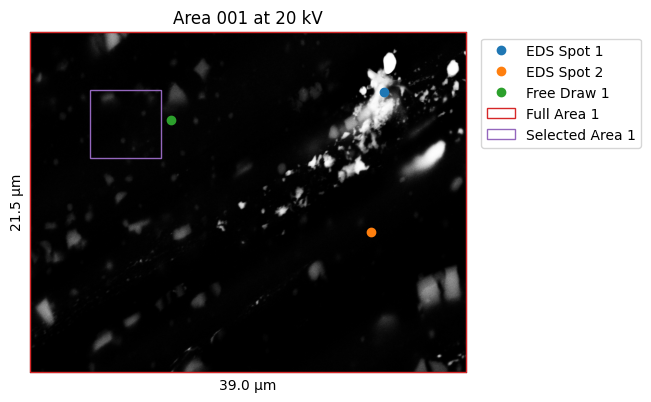

In [3]:
area_0d = "Area 001 spatial 0D"
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]
edx.plot_0D_image(exp, area_0d, mpl_colorlist=colors)
plt.show()

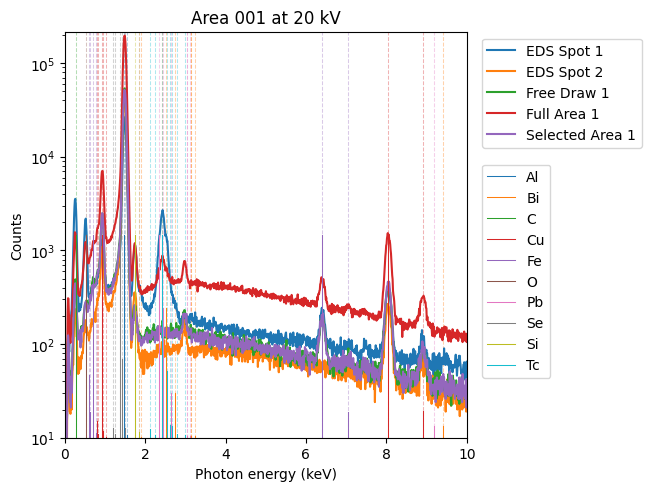

In [5]:
elements_0d = sorted({
    element
    for elements in exp[area_0d]["elements"]
    for element in elements
})
ax = edx.plot_0D_spectra(exp, area_0d, mpl_colorlist=colors,logscale_y_minimum=10)
edx.plot_xray_lines_exspy(ax, elements_0d, dashed=True)
ax.set_xlim([0,10])
plt.show()

Normalize the displayed spectra to the largest integrated count sum and use
a logarithmic axis to inspect weaker features. A true mask entry excludes the
corresponding measurement from plotting and reference selection.

In [ ]:
print(elements_0d)
# sort out the last element Tc 
elements=elements_0d[::-1]

['Al', 'Bi', 'C', 'Cu', 'Fe', 'O', 'Pb', 'Se', 'Si', 'Tc']


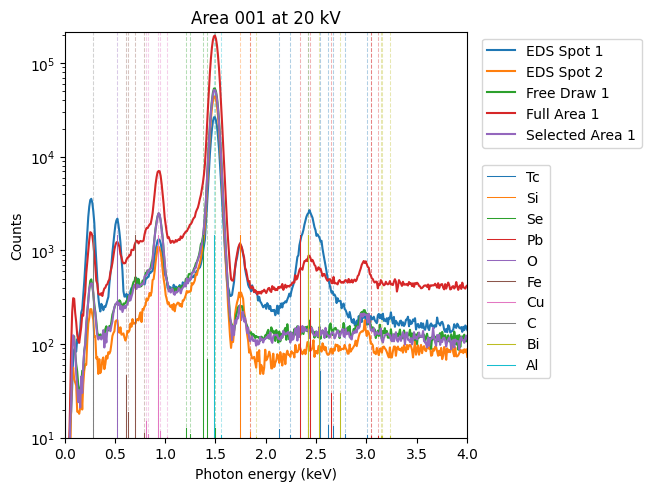

In [9]:
ax = edx.plot_0D_spectra(exp, area_0d, mpl_colorlist=colors,logscale_y_minimum=10)
edx.plot_xray_lines_exspy(ax, elements, dashed=True)
ax.set_xlim([0,4])
plt.show()

## Stored composition

The following table shows the first EDS Spot's stored weight fractions and the
atomic percentages calculated using atomic masses. Weight fractions retain the
file's numerical scale. The atomic percentages sum to 100 when the total is positive.

In [10]:
entry = exp[area_0d]
measurement_index = 0
print(entry["measurements"][measurement_index])
print(f"{'Element':<10}{'Weight fraction':>18}{'Atomic %':>14}")
for symbol, weight, atomic in zip(
    entry["elements"][measurement_index],
    entry["weight_fractions"][measurement_index],
    entry["atomic_percentages"][measurement_index],
):
    print(f"{symbol:<10}{weight:>18.5g}{atomic:>14.5g}")

EDS Spot 1
Element      Weight fraction      Atomic %
C                    0.50947        71.224
O                    0.12952        13.593
Al                   0.20919        13.018
Si                 0.0080047       0.47856
Fe                 0.0050519        0.1519
Cu                  0.022687       0.59945
Pb                  0.046823       0.37944
Bi                  0.069256       0.55645


## LineScan

Area 002 contains one LineScan. Its overview marks the start and end positions.
The profile plot uses distance from the start in micrometers and includes
SE and X-ray counts strips. Element masking accepts symbols such as `["Cu"]`.

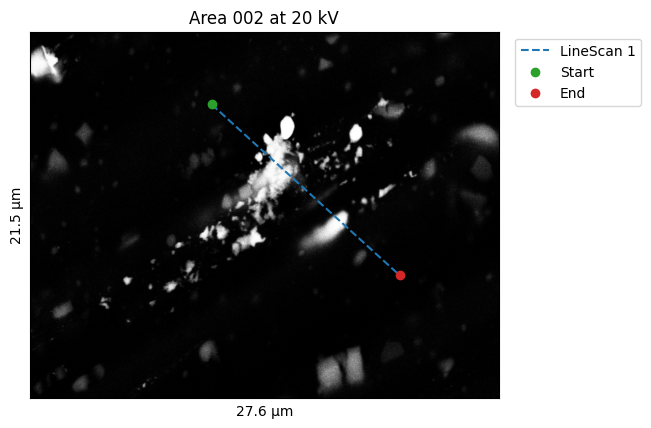

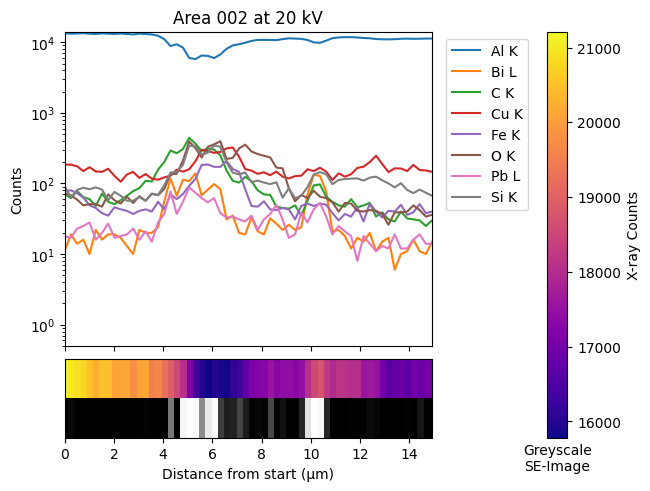

In [11]:
area_1d = "Area 002 spatial 1D"
edx.plot_1D_image(exp, area_1d)
plt.show()

edx.plot_1D_maps(exp, area_1d, index=0, mask=[],logscale_y=True)
plt.show()

The map spectrum compares the spatial average with the full spectrum at the
position containing the highest individual channel count. Its logarithmic lower
limit is the smallest positive value of the average spectrum.

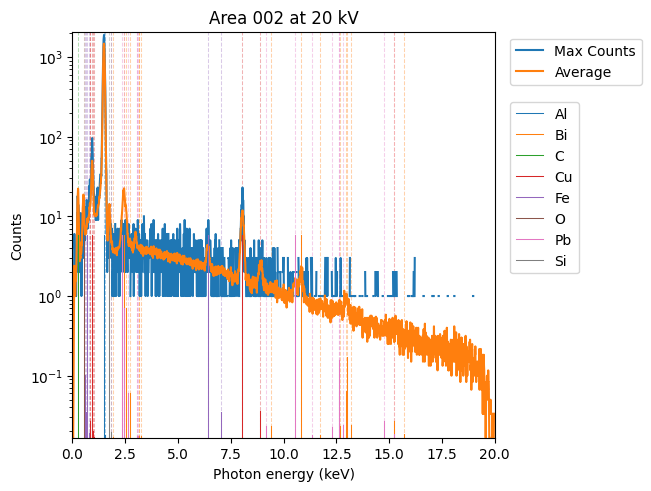

In [12]:
ax = edx.plot_spectrum_from_map(exp, area_1d, index=0, logscale_y=True)
edx.plot_xray_lines_exspy(ax, exp[area_1d]["elements"][0], dashed=True)
plt.show()

## Live Map

The overview uses the area's field-of-view image. The map panels show the selected
Live Map's SE signal, additive element overlay, X-ray counts, and individual
element maps. Each element image is scaled to its own peak. Set `grid_division=2`
for four quadrants, or use `1` to omit the grid.

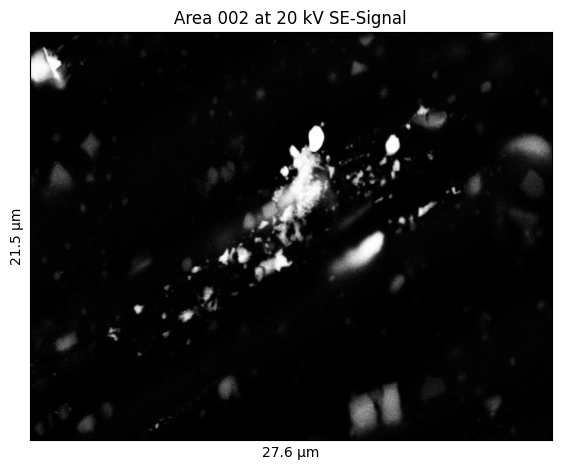

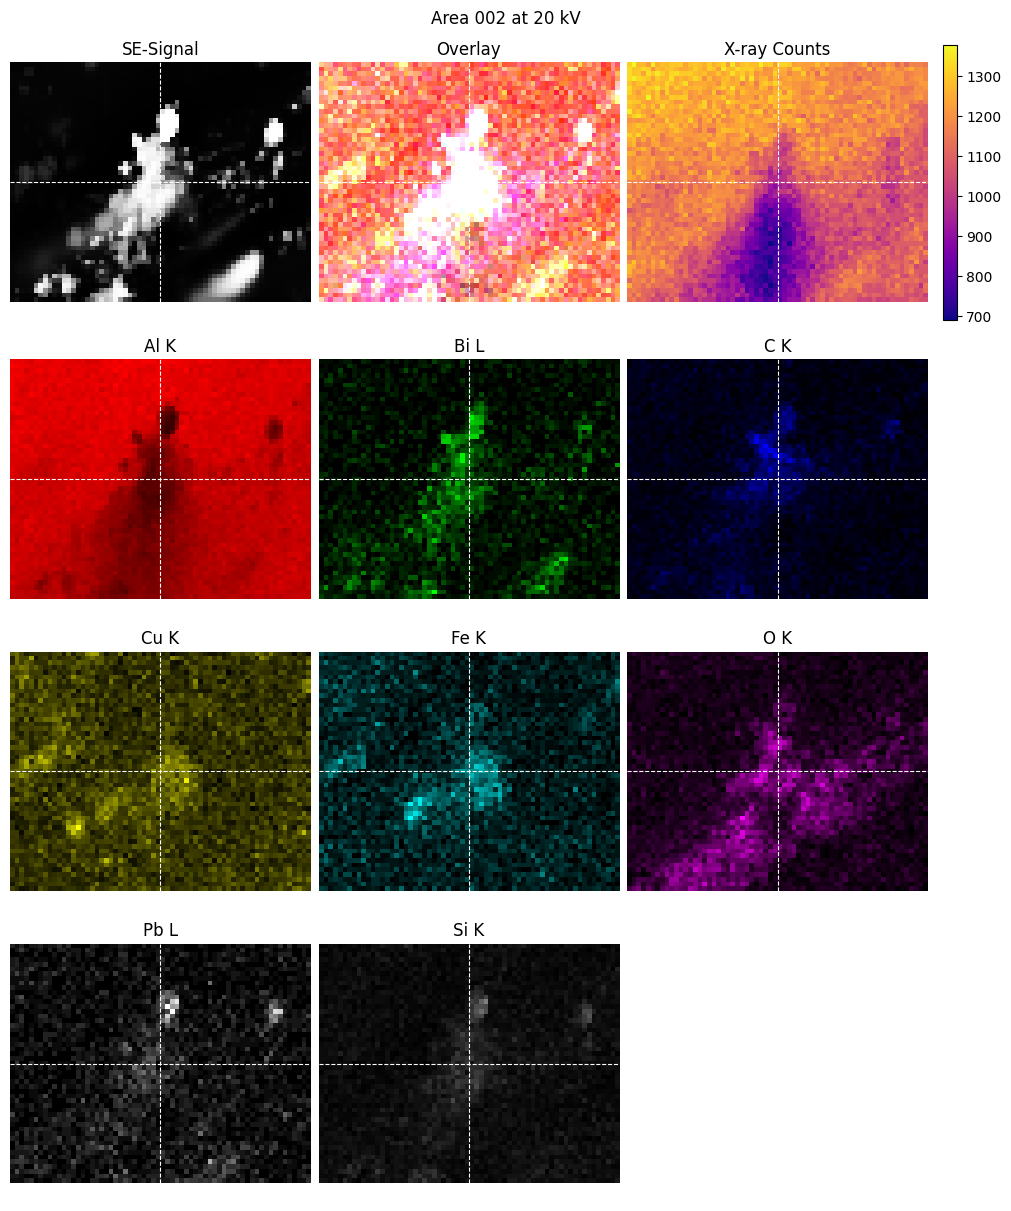

In [13]:
area_2d = "Area 002 spatial 2D"
edx.plot_2D_image(exp, area_2d, index=0)
plt.show()

edx.plot_2D_maps(exp, area_2d, index=0, mask=[], grid_division=2)
plt.show()

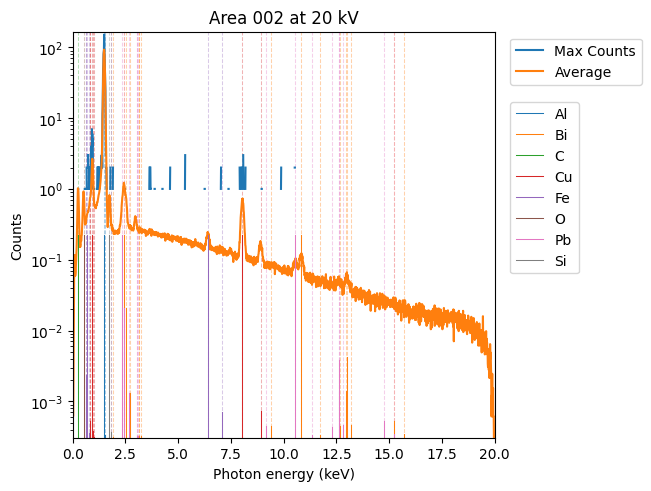

In [14]:
ax = edx.plot_spectrum_from_map(exp, area_2d, index=0, logscale_y=True)
edx.plot_xray_lines_exspy(ax, exp[area_2d]["elements"][0], dashed=True)
plt.show()

## Fit EDS Spot 1

Fit one spectrum explicitly with `edx.fit_eds_spectrum`. It returns the
total fitted spectrum, background, and peak metadata. The example fits from 0.2 keV to the beam energy and linearly extends the
background below the fitting interval. The returned arrays retain these lower
channels, which are marked by `fit_metadata['extrapolated_mask']`.
The extension is an estimate outside the fitted interval. Set
`fit_minimum_keV=0` to include those channels in the fit directly.

Set `force_positive_peaks=True` to constrain Gaussian amplitudes to zero or
positive values, including tied subsidiary lines. Its default is False.
The background-subtracted counts are used directly.

Choose `"polynomial"` (default), `"snip"`, or `"spline"` for the background.
Optional settings are `{"order": 4}` for the polynomial,
`{"window_keV": 0.4}` for the SNIP half-window, or
`{"smoothing": 1.0}` for the spline. Detector resolution is read from
the experiment metadata in eV.

In [15]:
background_method = "polynomial"
background_options = {}
force_positive_peaks = True
fit_minimum_keV = 0.2
extrapolate_background = True

fit_area = "Area 001 spatial 0D"
fit_entry = exp[fit_area]
measurement_name = "EDS Spot 1"
measurement_index = fit_entry["measurements"].index(measurement_name)
energy, counts = fit_entry["spectrum"][measurement_index]
metadata = fit_entry["metadata"][measurement_index]

fitted, background, fit_metadata = edx.fit_eds_spectrum(
    energy,
    counts,
    fit_entry["elements"][measurement_index],
    metadata["orbitals"],
    detector_resolution=metadata["DetectorResolution"],
    beam_voltage=fit_entry["BeamKV"][measurement_index],
    background_method=background_method,
    background_options=background_options,
    force_positive_peaks=force_positive_peaks,
    fit_minimum_keV=fit_minimum_keV,
    extrapolate_background=extrapolate_background,
)

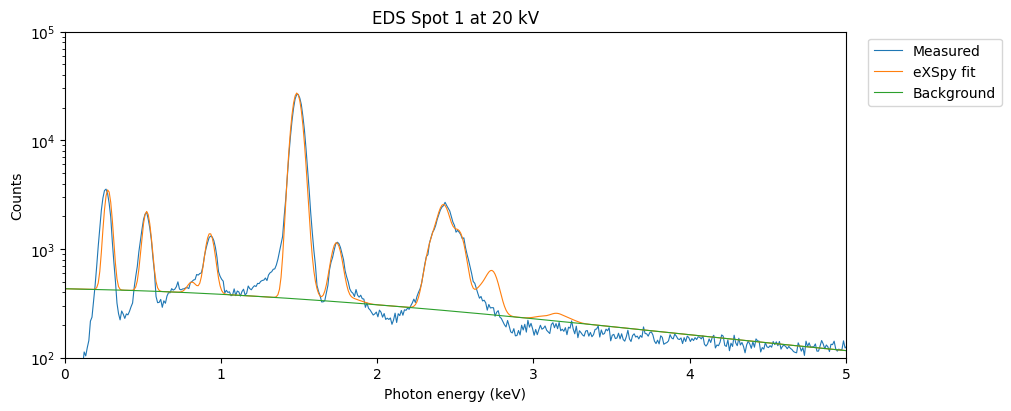

In [16]:
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.plot(energy, counts, label="Measured", linewidth=0.8)
ax.plot(energy, fitted, label="eXSpy fit", linewidth=0.8)
ax.semilogy(energy, background, label="Background", linewidth=0.8)
#ax.plot(energy, counts - fitted, label="Residual", linewidth=0.6)
ax.set(
    title=f"{measurement_name} at {fit_entry['BeamKV'][measurement_index]:g} kV",
    xlabel="Photon energy (keV)", ylabel="Counts",
    xlim=(0, 5),#fit_entry["BeamKV"][measurement_index]),
    ylim=(100,10**5)
)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

## Fit the whole area

The convenience function reads every spectrum's inputs from the experiment
dictionary. It stores each measurement's `fitted`, `background`, and
`fit_metadata` under `exp[fit_area]["fit"][measurement_name]`.

In [17]:
edx.fit_0D_measurement(
    exp,
    fit_area,
    background_method=background_method,
    background_options=background_options,
    force_positive_peaks=force_positive_peaks,
    fit_minimum_keV=fit_minimum_keV,
    extrapolate_background=extrapolate_background,
)
print("Stored fits:", list(exp[fit_area]["fit"]))

Stored fits: ['EDS Spot 1', 'EDS Spot 2', 'Free Draw 1', 'Full Area 1', 'Selected Area 1']


## Inspect fitted peaks for EDS Spot 1

Read the fit metadata directly from the experiment dictionary. The table includes
integrated counts, height in counts per channel, and the reference relative weight.
`Tied to` identifies the parent amplitude controlling a subsidiary line.
The annotated figure shows this measurement on a single panel.

Peak          Energy keV    Area counts      Height    Weight  Tied to
C_Ka              0.2774       17333.68     3096.31    1.0000  -
O_Ka              0.5249       11187.87     1806.60    1.0000  -
Fe_Ll             0.6152           0.00        0.00    0.3086  Fe_La
Fe_Ln             0.6282           0.00        0.00    0.1253  Fe_La
Fe_La             0.7045           0.00        0.00    1.0000  -
Fe_Lb3            0.7921           0.00        0.00    0.0245  Fe_La
Cu_Ll             0.8113         582.99       85.53    0.0840  Cu_La
Cu_Ln             0.8312         137.68       20.08    0.0198  Cu_La
Cu_La             0.9295        6939.48      983.24    1.0000  -
Cu_Lb1            0.9494         221.86       31.26    0.0320  Cu_La
Cu_Lb3            1.0225           7.91        1.09    0.0011  Cu_La
Al_Ka             1.4865      217849.52    26899.08    1.0000  -
Al_Kb             1.5596        2875.61      349.59    0.0132  Al_Ka
Si_Ka             1.7397        6981.46      818.45 

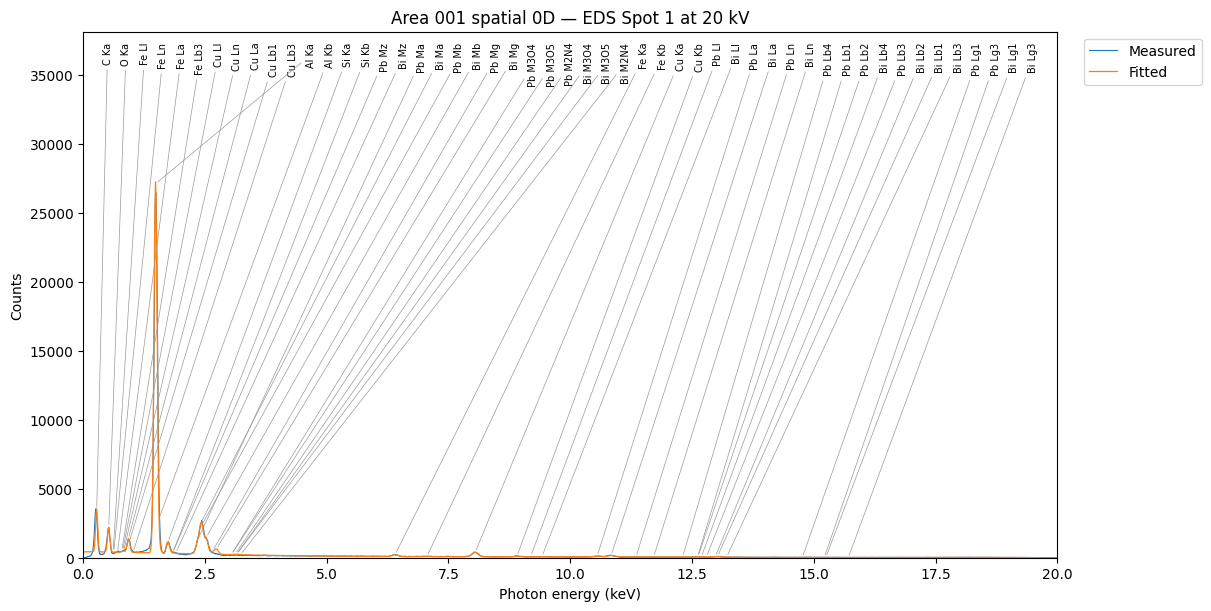

In [18]:
selected_measurement = "EDS Spot 1"
fit_metadata = exp[fit_area]["fit"][selected_measurement]["fit_metadata"]
print(f"{'Peak':<12}{'Energy keV':>12}{'Area counts':>15}{'Height':>12}{'Weight':>10}  Tied to")
for peak in fit_metadata["peaks"]:
    print(
        f"{peak['name']:<12}{peak['energy_keV']:>12.4f}"
        f"{peak['area_counts']:>15.2f}{peak['height_counts']:>12.2f}"
        f"{peak['relative_weight']:>10.4f}  {peak['tied_to'] or '-'}"
    )

ax = edx.plot_fitted_spectrum(
    fit_metadata,
    title=f"{fit_area} — {selected_measurement} at {fit_metadata['BeamKV']:g} kV",
)
plt.show()

## Optional PNG export

Uncomment the call below to create all standard figures directly in `./example_figures`.
Spectra are saved in both linear and logarithmic versions. The element list can
be overridden for 0D spectra with `element_list=["C", "Al", "Cu"]`.

In [15]:
# edx.create_all_figures(exp, "./example_figures", logscale_y_minimum=0.5)